<a href="https://colab.research.google.com/github/PatelHarshil2288/covid-19-trend-analysis/blob/main/COVID_19_Trend_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COVID-19 Trend Analysis with Python

## Project Objectives
- Clean and validate historical COVID-19 data.
- Analyze confirmed cases, deaths, recoveries, and active cases.
- Create interactive visualizations using Plotly.
- Forecast COVID-19 cases seven days ahead using Prophet.
- Compare historical trends and forecast results.

## Technologies
Python, Pandas, NumPy, Plotly, Prophet, Google Colab


In [5]:

# Step 1: Import libraries

import pandas as pd
import numpy as np
from IPython.display import display

# Step 2: Load the existing dataset from Colab

file_path = "/content/covid_19_clean_complete.csv"

df_raw = pd.read_csv(file_path)

# Step 3: Basic dataset inspection

print("COVID-19 Dataset Loaded Successfully!")
print("=" * 50)

print("Dataset Shape:", df_raw.shape)

print("\nColumn Names:")
print(df_raw.columns.tolist())

print("\nFirst 5 Rows:")
display(df_raw.head())

print("\nDataset Information:")
df_raw.info()

print("\nMissing Values:")
display(df_raw.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df_raw.duplicated().sum())

# Step 4: Check date coverage

df_raw["Date"] = pd.to_datetime(
    df_raw["Date"], errors="coerce"
)

print("\nDate Range:")
print("Start:", df_raw["Date"].min())
print("End:", df_raw["Date"].max())

print(
    "\nNumber of Countries/Regions:",
    df_raw["Country/Region"].nunique()
)


COVID-19 Dataset Loaded Successfully!
Dataset Shape: (49068, 10)

Column Names:
['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'WHO Region']

First 5 Rows:


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB

Missing Values:


,Missing Values
Province/State,34404
Country/Region,0
Lat,0
Long,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
WHO Region,0



Duplicate Rows: 0

Date Range:
Start: 2020-01-22 00:00:00
End: 2020-07-27 00:00:00

Number of Countries/Regions: 187


In [6]:

# ============================================
# STEP 2: DATA CLEANING AND VALIDATION
# ============================================

# Create a working copy of the original dataset
df = df_raw.copy()

print("Starting Data Cleaning and Validation")
print("=" * 50)

# 1. Standardize column names
df.columns = df.columns.str.strip()

# 2. Remove exact duplicate rows, if any
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("Exact duplicate rows removed:", duplicates_before)

# 3. Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# 4. Convert numerical columns to numeric format
numeric_columns = [
    "Lat", "Long", "Confirmed", "Deaths",
    "Recovered", "Active"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 5. Check missing values after conversion
print("\nMissing values after type conversion:")
display(df.isnull().sum().to_frame("Missing Values"))

# 6. Check invalid dates
invalid_dates = df["Date"].isna().sum()
print("\nInvalid dates:", invalid_dates)

# 7. Check negative case counts
case_columns = ["Confirmed", "Deaths", "Recovered", "Active"]

negative_counts = (df[case_columns] < 0).sum()

print("\nNegative values in case columns:")
display(negative_counts.to_frame("Negative Count"))

# 8. Check logical consistency of reported counts
inconsistent_confirmed = (
    df["Deaths"] + df["Recovered"] > df["Confirmed"]
)

print(
    "\nRows where deaths + recovered exceed confirmed:",
    inconsistent_confirmed.sum()
)

# 9. Check missing values in important fields
required_columns = [
    "Country/Region", "Date", "Confirmed",
    "Deaths", "Recovered", "Active"
]

missing_required = df[required_columns].isna().sum()

print("\nMissing values in required fields:")
display(missing_required.to_frame("Missing Values"))

# 10. Display dataset summary
print("\nDataset shape after initial cleaning:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Unique countries/regions:", df["Country/Region"].nunique())

print("\nData types after conversion:")
print(df.dtypes)

print("\nCleaning checks completed.")


Starting Data Cleaning and Validation
Exact duplicate rows removed: 0

Missing values after type conversion:


,Missing Values
Province/State,34404
Country/Region,0
Lat,0
Long,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
WHO Region,0



Invalid dates: 0

Negative values in case columns:


,Negative Count
Confirmed,0
Deaths,0
Recovered,0
Active,18



Rows where deaths + recovered exceed confirmed: 18

Missing values in required fields:


,Missing Values
Country/Region,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0



Dataset shape after initial cleaning: (49068, 10)
Date range: 2020-01-22 00:00:00 to 2020-07-27 00:00:00
Unique countries/regions: 187

Data types after conversion:
Province/State            object
Country/Region            object
Lat                      float64
Long                     float64
Date              datetime64[ns]
Confirmed                  int64
Deaths                     int64
Recovered                  int64
Active                     int64
WHO Region                object
dtype: object

Cleaning checks completed.


In [7]:

# ============================================
# STEP 3: INVESTIGATE SUSPICIOUS RECORDS
# ============================================

# Create a mask for suspicious records
negative_active = df["Active"] < 0

deaths_recovered_exceed_confirmed = (
    df["Deaths"] + df["Recovered"] > df["Confirmed"]
)

# Combine both conditions
suspicious_mask = (
    negative_active | deaths_recovered_exceed_confirmed
)

# Extract suspicious rows for investigation
suspicious_records = df.loc[suspicious_mask].copy()

# Calculate the expected active cases
suspicious_records["Calculated_Active"] = (
    suspicious_records["Confirmed"]
    - suspicious_records["Deaths"]
    - suspicious_records["Recovered"]
)

# Calculate the difference from the reported active cases
suspicious_records["Active_Difference"] = (
    suspicious_records["Active"]
    - suspicious_records["Calculated_Active"]
)

# Display the findings
print("Total suspicious records:", len(suspicious_records))

print(
    "Records with negative Active:",
    negative_active.sum()
)

print(
    "Records where deaths + recoveries exceed confirmed:",
    deaths_recovered_exceed_confirmed.sum()
)

print(
    "Records satisfying both conditions:",
    (
        negative_active
        & deaths_recovered_exceed_confirmed
    ).sum()
)

print("\nSuspicious Records for Review:")

columns_to_review = [
    "Province/State",
    "Country/Region",
    "Date",
    "Confirmed",
    "Deaths",
    "Recovered",
    "Active",
    "Calculated_Active",
    "Active_Difference"
]

display(
    suspicious_records[columns_to_review]
    .sort_values(["Country/Region", "Date"])
    .reset_index(drop=True)
)


Total suspicious records: 18
Records with negative Active: 18
Records where deaths + recoveries exceed confirmed: 18
Records satisfying both conditions: 18

Suspicious Records for Review:


,Province/State,Country/Region,Date,Confirmed,Deaths,Recovered,Active,Calculated_Active,Active_Difference
0,Hainan,China,2020-03-24,168,6,168,-6,-6,0
1,Hainan,China,2020-03-25,168,6,168,-6,-6,0
2,Hainan,China,2020-03-26,168,6,168,-6,-6,0
3,Hainan,China,2020-03-27,168,6,168,-6,-6,0
4,Hainan,China,2020-03-28,168,6,168,-6,-6,0
5,Hainan,China,2020-03-29,168,6,168,-6,-6,0
6,Hainan,China,2020-03-30,168,6,168,-6,-6,0
7,Hainan,China,2020-03-31,168,6,168,-6,-6,0
8,Hainan,China,2020-04-01,168,6,168,-6,-6,0
9,NaN,Liechtenstein,2020-06-23,82,2,81,-1,-1,0


In [8]:

# ============================================
# STEP 4: CREATE THE CLEANED DATASET
# ============================================

# Preserve the working dataset and its original values
df_clean = df.copy()

# Flag records with inconsistent case counts
df_clean["Data_Quality_Issue"] = (
    (df_clean["Active"] < 0) |
    (
        df_clean["Deaths"] + df_clean["Recovered"]
        > df_clean["Confirmed"]
    )
)

# Add a calculated active-case column for validation
df_clean["Calculated_Active"] = (
    df_clean["Confirmed"]
    - df_clean["Deaths"]
    - df_clean["Recovered"]
)

# Create a quality summary
quality_summary = pd.DataFrame({
    "Metric": [
        "Original records",
        "Records retained",
        "Exact duplicate rows remaining",
        "Invalid dates",
        "Records flagged for inconsistent case counts",
        "Records with missing required fields"
    ],
    "Value": [
        len(df_raw),
        len(df_clean),
        df_clean.duplicated().sum(),
        df_clean["Date"].isna().sum(),
        df_clean["Data_Quality_Issue"].sum(),
        df_clean[
            [
                "Country/Region", "Date", "Confirmed",
                "Deaths", "Recovered", "Active"
            ]
        ].isna().any(axis=1).sum()
    ]
})

print("DATA QUALITY SUMMARY")
display(quality_summary)

# Create a separate table for flagged records
df_quality_issues = df_clean[
    df_clean["Data_Quality_Issue"]
].copy()

# Save cleaned data and quality issues
df_clean.to_csv(
    "covid_19_cleaned.csv",
    index=False
)

df_quality_issues.to_csv(
    "covid_19_data_quality_issues.csv",
    index=False
)

print("\nCleaned dataset shape:", df_clean.shape)
print("Flagged records:", len(df_quality_issues))
print("Cleaned dataset saved successfully.")
print("Quality issues report saved successfully.")


DATA QUALITY SUMMARY


,Metric,Value
0,Original records,49068
1,Records retained,49068
2,Exact duplicate rows remaining,0
3,Invalid dates,0
4,Records flagged for inconsistent case counts,18
5,Records with missing required fields,0



Cleaned dataset shape: (49068, 12)
Flagged records: 18
Cleaned dataset saved successfully.
Quality issues report saved successfully.


In [9]:

# ============================================
# STEP 5: PREPARE TIME-SERIES DATA
# ============================================

# 1. Global daily summary
global_daily = (
    df_clean.groupby("Date", as_index=False)
    .agg({
        "Confirmed": "sum",
        "Deaths": "sum",
        "Recovered": "sum",
        "Active": "sum"
    })
    .sort_values("Date")
    .reset_index(drop=True)
)

# 2. Calculate daily changes from cumulative counts
for column in ["Confirmed", "Deaths", "Recovered"]:
    global_daily[f"Daily_New_{column}"] = (
        global_daily[column].diff()
    )

# The first date has no preceding observation
global_daily.loc[
    0,
    [
        "Daily_New_Confirmed",
        "Daily_New_Deaths",
        "Daily_New_Recovered"
    ]
] = np.nan

# 3. Prepare India-specific daily data
india_daily = (
    df_clean[
        df_clean["Country/Region"].str.strip().str.lower()
        == "india"
    ]
    .groupby("Date", as_index=False)
    .agg({
        "Confirmed": "sum",
        "Deaths": "sum",
        "Recovered": "sum",
        "Active": "sum"
    })
    .sort_values("Date")
    .reset_index(drop=True)
)

for column in ["Confirmed", "Deaths", "Recovered"]:
    india_daily[f"Daily_New_{column}"] = (
        india_daily[column].diff()
    )

india_daily.loc[
    0,
    [
        "Daily_New_Confirmed",
        "Daily_New_Deaths",
        "Daily_New_Recovered"
    ]
] = np.nan

# 4. Display summaries
print("GLOBAL TIME-SERIES SUMMARY")
print("Number of dates:", len(global_daily))
display(global_daily.head())
display(global_daily.tail())

print("\nINDIA TIME-SERIES SUMMARY")
print("Number of dates:", len(india_daily))
display(india_daily.head())
display(india_daily.tail())

# 5. Save the aggregated datasets
global_daily.to_csv("covid_19_global_daily.csv", index=False)
india_daily.to_csv("covid_19_india_daily.csv", index=False)

print("\nGlobal and India time-series files saved successfully.")


GLOBAL TIME-SERIES SUMMARY
Number of dates: 188


,Date,Confirmed,Deaths,Recovered,Active,Daily_New_Confirmed,Daily_New_Deaths,Daily_New_Recovered
0,2020-01-22,555,17,28,510,NaN,NaN,NaN
1,2020-01-23,654,18,30,606,99.0,1.0,2.0
2,2020-01-24,941,26,36,879,287.0,8.0,6.0
3,2020-01-25,1434,42,39,1353,493.0,16.0,3.0
4,2020-01-26,2118,56,52,2010,684.0,14.0,13.0


,Date,Confirmed,Deaths,Recovered,Active,Daily_New_Confirmed,Daily_New_Deaths,Daily_New_Recovered
183,2020-07-23,15510481,633506,8710969,6166006,282756.0,9966.0,169714.0
184,2020-07-24,15791645,639650,8939705,6212290,281164.0,6144.0,228736.0
185,2020-07-25,16047190,644517,9158743,6243930,255545.0,4867.0,219038.0
186,2020-07-26,16251796,648621,9293464,6309711,204606.0,4104.0,134721.0
187,2020-07-27,16480485,654036,9468087,6358362,228689.0,5415.0,174623.0



INDIA TIME-SERIES SUMMARY
Number of dates: 188


,Date,Confirmed,Deaths,Recovered,Active,Daily_New_Confirmed,Daily_New_Deaths,Daily_New_Recovered
0,2020-01-22,0,0,0,0,NaN,NaN,NaN
1,2020-01-23,0,0,0,0,0.0,0.0,0.0
2,2020-01-24,0,0,0,0,0.0,0.0,0.0
3,2020-01-25,0,0,0,0,0.0,0.0,0.0
4,2020-01-26,0,0,0,0,0.0,0.0,0.0


,Date,Confirmed,Deaths,Recovered,Active,Daily_New_Confirmed,Daily_New_Deaths,Daily_New_Recovered
183,2020-07-23,1288108,30601,817209,440298,49310.0,740.0,34602.0
184,2020-07-24,1337024,31358,849432,456234,48916.0,757.0,32223.0
185,2020-07-25,1385635,32060,885573,468002,48611.0,702.0,36141.0
186,2020-07-26,1435616,32771,917568,485277,49981.0,711.0,31995.0
187,2020-07-27,1480073,33408,951166,495499,44457.0,637.0,33598.0



Global and India time-series files saved successfully.


In [10]:

# ============================================
# STEP 6: INTERACTIVE PLOTLY VISUALIZATIONS
# ============================================

import plotly.express as px

# 1. Global cumulative trends
global_long = global_daily.melt(
    id_vars="Date",
    value_vars=["Confirmed", "Deaths", "Recovered"],
    var_name="Metric",
    value_name="Cases"
)

fig_global = px.line(
    global_long,
    x="Date",
    y="Cases",
    color="Metric",
    title="Global COVID-19: Confirmed Cases, Deaths and Recoveries",
    labels={"Cases": "Reported cumulative count", "Date": "Date"},
    template="plotly_white"
)

fig_global.update_layout(
    hovermode="x unified",
    legend_title="Metric"
)

fig_global.show()


# 2. Global daily new confirmed cases
fig_global_daily = px.bar(
    global_daily,
    x="Date",
    y="Daily_New_Confirmed",
    title="Global COVID-19: Daily Change in Confirmed Cases",
    labels={
        "Daily_New_Confirmed": "Change in confirmed cases",
        "Date": "Date"
    },
    template="plotly_white"
)

fig_global_daily.update_layout(hovermode="x unified")
fig_global_daily.show()


# 3. India cumulative trends
india_long = india_daily.melt(
    id_vars="Date",
    value_vars=["Confirmed", "Deaths", "Recovered"],
    var_name="Metric",
    value_name="Cases"
)

fig_india = px.line(
    india_long,
    x="Date",
    y="Cases",
    color="Metric",
    title="India COVID-19: Confirmed Cases, Deaths and Recoveries",
    labels={"Cases": "Reported cumulative count", "Date": "Date"},
    template="plotly_white"
)

fig_india.update_layout(
    hovermode="x unified",
    legend_title="Metric"
)

fig_india.show()


# 4. India daily new confirmed cases
fig_india_daily = px.bar(
    india_daily,
    x="Date",
    y="Daily_New_Confirmed",
    title="India COVID-19: Daily Change in Confirmed Cases",
    labels={
        "Daily_New_Confirmed": "Change in confirmed cases",
        "Date": "Date"
    },
    template="plotly_white"
)

fig_india_daily.update_layout(hovermode="x unified")
fig_india_daily.show()

print("All four interactive visualizations generated successfully.")


All four interactive visualizations generated successfully.


In [11]:

# ============================================
# STEP 7: COUNTRY AND REGIONAL ANALYSIS
# ============================================

import plotly.express as px

# 1. Latest available record for each country
latest_date = df_clean["Date"].max()

latest_records = df_clean[
    df_clean["Date"] == latest_date
].copy()

# Aggregate provinces into country-level totals
country_summary = (
    latest_records.groupby("Country/Region", as_index=False)
    .agg({
        "Confirmed": "sum",
        "Deaths": "sum",
        "Recovered": "sum",
        "Active": "sum"
    })
    .sort_values("Confirmed", ascending=False)
)

print("TOP 10 COUNTRIES BY CONFIRMED CASES")
display(country_summary.head(10))

# 2. Interactive top 10 countries chart
top10_countries = country_summary.head(10).sort_values(
    "Confirmed", ascending=True
)

fig_countries = px.bar(
    top10_countries,
    x="Confirmed",
    y="Country/Region",
    orientation="h",
    color="Confirmed",
    title=f"Top 10 Countries by Confirmed Cases ({latest_date:%d %b %Y})",
    labels={
        "Confirmed": "Confirmed cases",
        "Country/Region": "Country"
    },
    template="plotly_white"
)

fig_countries.show()

# 3. WHO regional summary for the latest date
regional_summary = (
    latest_records.groupby("WHO Region", as_index=False)
    .agg({
        "Confirmed": "sum",
        "Deaths": "sum",
        "Recovered": "sum",
        "Active": "sum"
    })
    .sort_values("Confirmed", ascending=False)
)

print("\nWHO REGIONAL SUMMARY")
display(regional_summary)

# 4. Interactive regional comparison
fig_regions = px.bar(
    regional_summary,
    x="WHO Region",
    y="Confirmed",
    color="WHO Region",
    title=f"Confirmed Cases by WHO Region ({latest_date:%d %b %Y})",
    labels={"Confirmed": "Confirmed cases"},
    template="plotly_white"
)

fig_regions.update_layout(showlegend=False)
fig_regions.show()

# 5. India compared with the global total
india_latest = country_summary[
    country_summary["Country/Region"] == "India"
]

print("\nINDIA'S LATEST AVAILABLE SUMMARY")
display(india_latest)

# 6. Save country and regional summaries
country_summary.to_csv(
    "covid_19_country_summary.csv", index=False
)

regional_summary.to_csv(
    "covid_19_regional_summary.csv", index=False
)

print("\nCountry and regional analysis completed.")


TOP 10 COUNTRIES BY CONFIRMED CASES


,Country/Region,Confirmed,Deaths,Recovered,Active
173,US,4290259,148011,1325804,2816444
23,Brazil,2442375,87618,1846641,508116
79,India,1480073,33408,951166,495499
138,Russia,816680,13334,602249,201097
154,South Africa,452529,7067,274925,170537
111,Mexico,395489,44022,303810,47657
132,Peru,389717,18418,272547,98752
35,Chile,347923,9187,319954,18782
177,United Kingdom,301708,45844,1437,254427
81,Iran,293606,15912,255144,22550



WHO REGIONAL SUMMARY


,WHO Region,Confirmed,Deaths,Recovered,Active
1,Americas,8839286,342732,4468616,4027938
3,Europe,3299523,211144,1993723,1094656
4,South-East Asia,1835297,41349,1156933,637015
2,Eastern Mediterranean,1490744,38339,1201400,251005
0,Africa,723207,12223,440645,270339
5,Western Pacific,292428,8249,206770,77409



INDIA'S LATEST AVAILABLE SUMMARY


,Country/Region,Confirmed,Deaths,Recovered,Active
79,India,1480073,33408,951166,495499



Country and regional analysis completed.


In [12]:

# Install the Prophet forecasting library
%pip install prophet -q


In [13]:

# ============================================
# STEP 8: PREPARE DATA FOR PROPHET
# ============================================

from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Prophet requires columns named ds and y
forecast_data = global_daily[["Date", "Confirmed"]].copy()

forecast_data = forecast_data.rename(
    columns={
        "Date": "ds",
        "Confirmed": "y"
    }
)

forecast_data = forecast_data.sort_values("ds")
forecast_data = forecast_data.dropna(
    subset=["ds", "y"]
).reset_index(drop=True)

print("Forecast dataset shape:", forecast_data.shape)
print("\nFirst 5 rows:")
display(forecast_data.head())

print("\nLast 5 rows:")
display(forecast_data.tail())

print("\nForecast target: Global cumulative confirmed cases")
print("First date:", forecast_data["ds"].min())
print("Last date:", forecast_data["ds"].max())


Forecast dataset shape: (188, 2)

First 5 rows:


,ds,y
0,2020-01-22,555
1,2020-01-23,654
2,2020-01-24,941
3,2020-01-25,1434
4,2020-01-26,2118



Last 5 rows:


,ds,y
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796
187,2020-07-27,16480485



Forecast target: Global cumulative confirmed cases
First date: 2020-01-22 00:00:00
Last date: 2020-07-27 00:00:00


In [14]:

# ============================================
# STEP 9: TRAIN AND EVALUATE PROPHET
# ============================================

# Split the data chronologically
test_days = 14

train_data = forecast_data.iloc[:-test_days].copy()
test_data = forecast_data.iloc[-test_days:].copy()

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))
print("Training ends:", train_data["ds"].max())
print("Testing starts:", test_data["ds"].min())

# Train Prophet using historical data only
model_eval = Prophet(
    daily_seasonality=False,
    weekly_seasonality=True,
    yearly_seasonality=False
)

model_eval.fit(train_data)

# Forecast across the held-out test period
test_future = test_data[["ds"]].copy()
test_predictions = model_eval.predict(test_future)

# Compare predictions with actual values
evaluation = test_data[["ds", "y"]].copy()
evaluation["Predicted"] = test_predictions["yhat"].values

# Calculate evaluation metrics
mae = mean_absolute_error(
    evaluation["y"],
    evaluation["Predicted"]
)

rmse = np.sqrt(
    mean_squared_error(
        evaluation["y"],
        evaluation["Predicted"]
    )
)

print("\nMODEL EVALUATION")
print("-" * 40)
print(f"Mean Absolute Error (MAE): {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")

print("\nActual vs Predicted Cases:")
display(evaluation)

# Visualize test predictions against actual observations
fig_eval = px.line(
    evaluation,
    x="ds",
    y=["y", "Predicted"],
    title="Prophet Evaluation: Actual vs Predicted Global Cases",
    labels={
        "ds": "Date",
        "value": "Cumulative confirmed cases",
        "variable": "Series"
    },
    template="plotly_white"
)

fig_eval.update_layout(hovermode="x unified")
fig_eval.show()


Training observations: 174
Testing observations: 14
Training ends: 2020-07-13 00:00:00
Testing starts: 2020-07-14 00:00:00

MODEL EVALUATION
----------------------------------------
Mean Absolute Error (MAE): 844,762.48
Root Mean Squared Error (RMSE): 899,652.37

Actual vs Predicted Cases:


,ds,y,Predicted
174,2020-07-14,13328867,1.294836e+07
175,2020-07-15,13559984,1.311864e+07
176,2020-07-16,13812525,1.329281e+07
177,2020-07-17,14054563,1.346883e+07
178,2020-07-18,14292198,1.364164e+07
179,2020-07-19,14506845,1.380664e+07
180,2020-07-20,14713623,1.396861e+07
181,2020-07-21,14947078,1.412083e+07
182,2020-07-22,15227725,1.429111e+07
183,2020-07-23,15510481,1.446528e+07


SEVEN-DAY GLOBAL COVID-19 FORECAST


,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,16320086,16212737,16436115
189,2020-07-29,16529892,16427042,16637103
190,2020-07-30,16743828,16630331,16846663
191,2020-07-31,16959069,16860446,17059159
192,2020-08-01,17166688,17054980,17271787
193,2020-08-02,17364191,17258487,17482093
194,2020-08-03,17558803,17451891,17675900



Forecast CSV saved successfully.


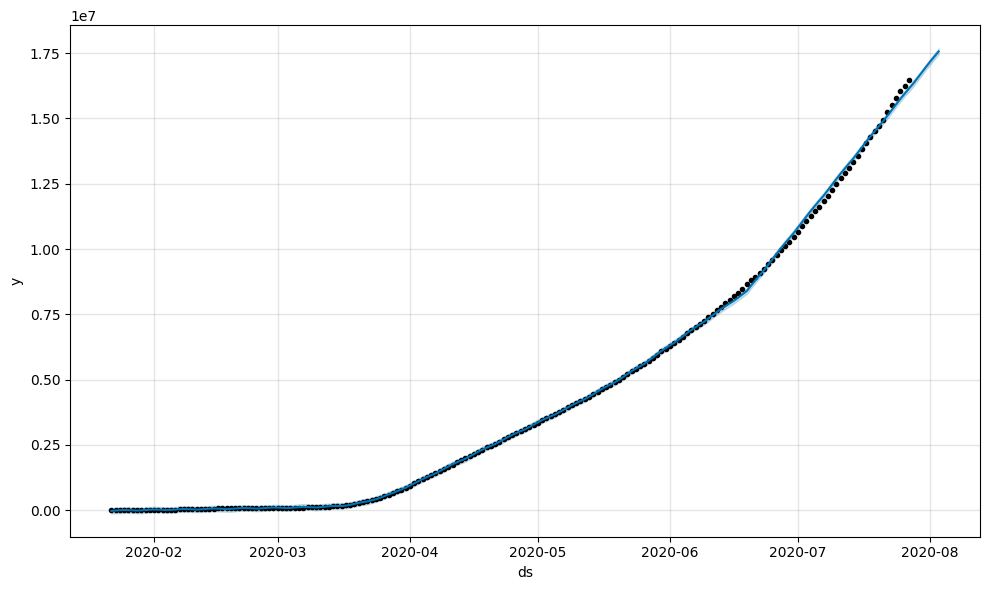

In [15]:

# ============================================
# STEP 10: FINAL SEVEN-DAY FORECAST
# ============================================

# Train the final model on all available observations
final_model = Prophet(
    daily_seasonality=False,
    weekly_seasonality=True,
    yearly_seasonality=False
)

final_model.fit(forecast_data)

# Generate seven future dates
future_dates = final_model.make_future_dataframe(
    periods=7,
    freq="D"
)

# Predict historical and future values
forecast = final_model.predict(future_dates)

# Select only the seven future dates
future_forecast = forecast.loc[
    forecast["ds"] > forecast_data["ds"].max(),
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

# Ensure forecast counts and lower bounds are nonnegative
for column in ["yhat", "yhat_lower", "yhat_upper"]:
    future_forecast[column] = (
        future_forecast[column].clip(lower=0).round().astype(int)
    )

print("SEVEN-DAY GLOBAL COVID-19 FORECAST")
display(future_forecast)

# Plot the model forecast
fig_forecast = final_model.plot(forecast)

fig_forecast.show()

# Create an interactive Plotly forecast chart
fig_interactive = px.line(
    forecast,
    x="ds",
    y="yhat",
    title="Global COVID-19: Seven-Day Prophet Forecast",
    labels={
        "ds": "Date",
        "yhat": "Predicted cumulative confirmed cases"
    },
    template="plotly_white"
)

# Add prediction interval
fig_interactive.add_scatter(
    x=forecast["ds"],
    y=forecast["yhat_upper"],
    mode="lines",
    line=dict(width=0),
    showlegend=False,
    hoverinfo="skip"
)

fig_interactive.add_scatter(
    x=forecast["ds"],
    y=forecast["yhat_lower"],
    mode="lines",
    line=dict(width=0),
    fill="tonexty",
    fillcolor="rgba(99, 110, 250, 0.15)",
    name="Prediction interval",
    hoverinfo="skip"
)

# Overlay historical observations
fig_interactive.add_scatter(
    x=forecast_data["ds"],
    y=forecast_data["y"],
    mode="markers",
    name="Actual historical cases",
    marker=dict(size=4)
)

fig_interactive.show()

# Save forecast results
future_forecast.to_csv(
    "covid_19_seven_day_forecast.csv",
    index=False
)

print("\nForecast CSV saved successfully.")
